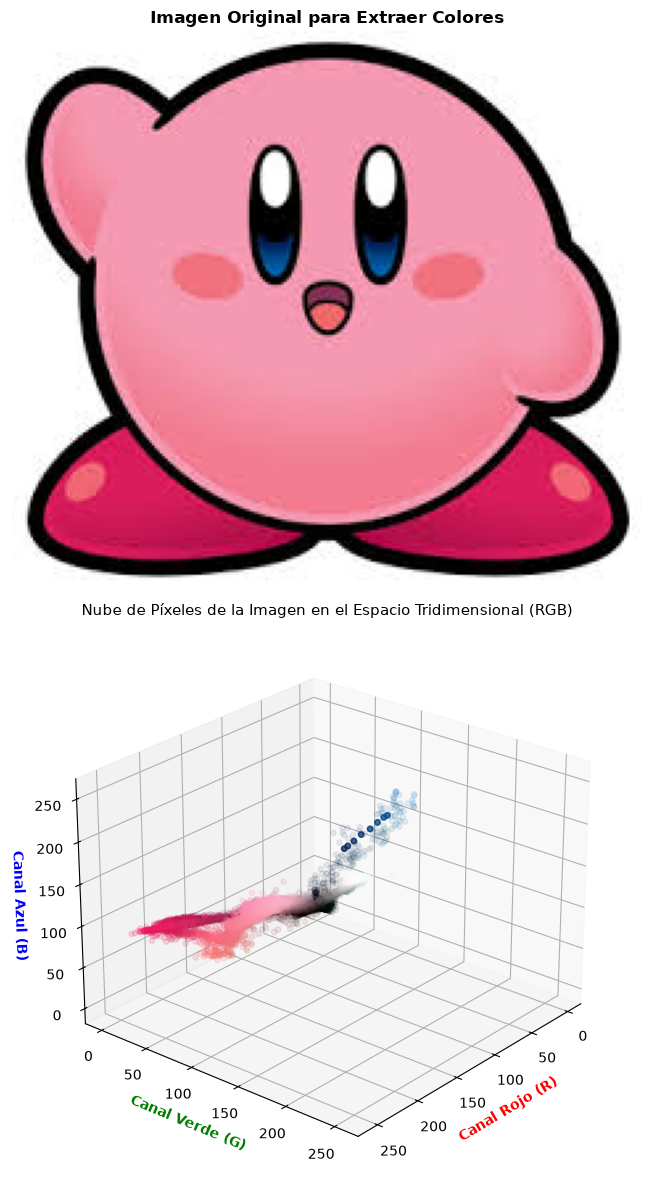

In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
from PIL import Image 

# 1. Cargar la imagen y preparar la matriz
image_path = '/home/SUSANA/diplomado-ciencia-de-datos/asset/images.jpg' 
image = Image.open(image_path).convert('RGB') 
img_array = np.array(image) 

h, w, c = img_array.shape 
X = img_array.reshape(-1, 3) 
pixel_colors = X / 255.0

# =========================================================================
# DISEÑO VERTICAL EXACTO: FOTO ARRIBA, GRÁFICA 3D ABAJO
# =========================================================================

# Creamos un lienzo que contenga 2 filas de gráficas (una arriba de otra)
fig = plt.figure(figsize=(8, 12))

# --- GRÁFICA 1: La foto original en la parte superior ---
ax1 = fig.add_subplot(2, 1, 1)  # 2 filas, 1 columna, posición 1 (arriba)
ax1.imshow(img_array)
ax1.axis('off')
ax1.set_title("Imagen Original para Extraer Colores", fontsize=12, fontweight='bold')

# --- GRÁFICA 2: La nube 3D en la parte inferior ---
ax2 = fig.add_subplot(2, 1, 2, projection='3d')  # 2 filas, 1 columna, posición 2 (abajo)
r = X[:, 0] 
g = X[:, 1] 
b = X[:, 2] 

# Dibujar la dispersión 3D
ax2.scatter(r, g, b, c=pixel_colors, s=15, alpha=0.5) 

# Configurar nombres de los ejes
ax2.set_xlabel('Canal Rojo (R)', color='red', fontweight='bold') 
ax2.set_ylabel('Canal Verde (G)', color='green', fontweight='bold') 
ax2.set_zlabel('Canal Azul (B)', color='blue', fontweight='bold') 
ax2.set_title('Nube de Píxeles de la Imagen en el Espacio Tridimensional (RGB)', fontsize=11) 

# Ajustar la inclinación de la vista
ax2.view_init(elev=25, azim=40) 

# Mostrar todo el conjunto unificado
plt.tight_layout()
plt.show()

=== INICIANDO CLUSTERIZACIÓN PARA: /home/SUSANA/diplomado-ciencia-de-datos/asset/images.jpg ===
Dimensiones de la imagen: 211x239 píxeles.
Buscando los 15 colores dominantes...



Época 1 completada.
Época 2 completada.
Época 3 completada.
Época 4 completada.
Época 5 completada.
Época 6 completada.
Época 7 completada.
Época 8 completada.
Época 9 completada.
Época 10 completada.
Época 11 completada.
Época 12 completada.
Época 13 completada.
Época 14 completada.
Época 15 completada.
Época 16 completada.
Época 17 completada.
Época 18 completada.
Época 19 completada.
Época 20 completada.

¡Proceso de clustering terminado!


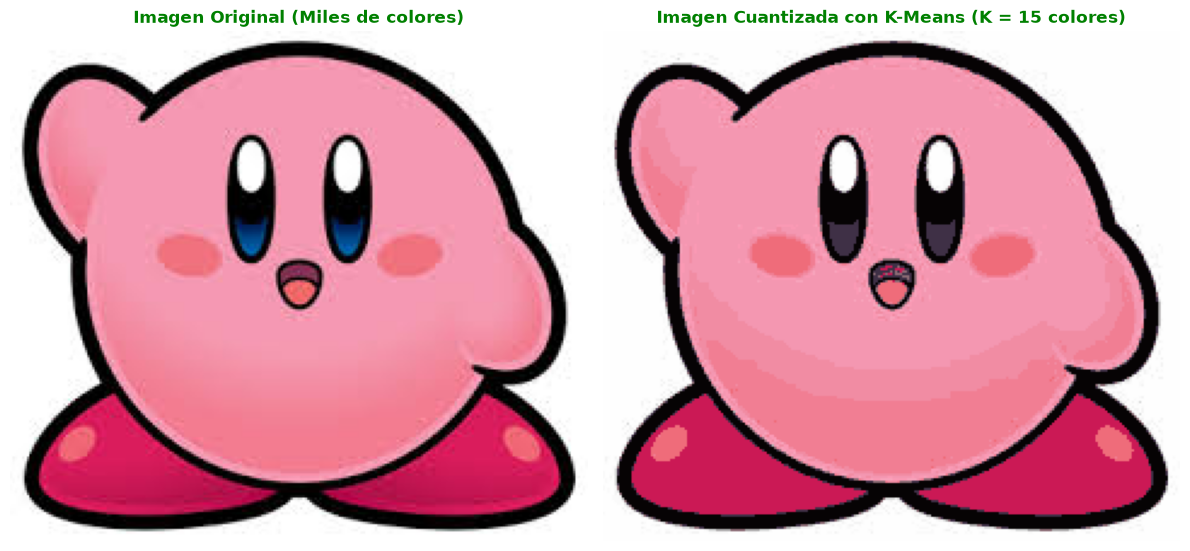


¡Listo! La imagen ha sido comprimida y resumida con éxito de millones de colores a solo 15 colores dominantes.


In [4]:
import numpy as np 
import matplotlib.pyplot as plt 
from PIL import Image 

# =========================================================================
# CONFIGURACIÓN DEL EXPERIMENTO (Aquí es donde controlas todo)
# =========================================================================

image_path = '/home/SUSANA/diplomado-ciencia-de-datos/asset/images.jpg'   # <--- MODIFICA AQUÍ: Pon el nombre de tu nueva foto
K = 15                           # <--- MODIFICA AQUÍ: Cambia el número de colores (Prueba 2, 5, 8...)
epochs = 20                          # <--- Opcional: Sube a 20 si usas un K muy alto


# =========================================================================
# 1. CARGAR Y REFORMAR LA IMAGEN
# =========================================================================
image = Image.open(image_path).convert('RGB') 
img_array = np.array(image) 
h, w, c = img_array.shape 
X = img_array.reshape(-1, 3) 

# Inicializar centroides aleatorios
np.random.seed(42)
random_indices = np.random.choice(X.shape[0], K, replace=False)
centroids = X[random_indices].astype(float)

print(f"=== INICIANDO CLUSTERIZACIÓN PARA: {image_path} ===")
print(f"Dimensiones de la imagen: {h}x{w} píxeles.")
print(f"Buscando los {K} colores dominantes...\n")


# =========================================================================
# 2. BUCLE DE ENTRENAMIENTO DE K-MEANS
# =========================================================================
for epoch in range(epochs):
    # Calcular distancias y asignar etiquetas
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    labels = np.argmin(distances, axis=1)
    
    # Calcular nuevos centros de color
    new_centroids = np.array([X[labels == i].mean(axis=0) if np.sum(labels == i) > 0 else centroids[i] for i in range(K)])
    
    # Revisar si los colores ya no cambian (convergencia)
    if np.allclose(centroids, new_centroids):
        print(f"¡K-Means convergió con éxito en la época {epoch + 1}!")
        break
        
    centroids = new_centroids
    print(f"Época {epoch + 1} completada.")

print("\n¡Proceso de clustering terminado!")


# =========================================================================
# 3. GENERAR RESULTADOS VISUALES (Fotos lado a lado y mensaje de éxito)
# =========================================================================
# Reconstruir la imagen comprimida
X_reconstructed = centroids[labels].astype(np.uint8)
img_reconstructed = X_reconstructed.reshape(h, w, c)

# Configurar el lienzo para poner las imágenes juntas
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Foto Original (Izquierda)
axes[0].imshow(img_array)
axes[0].axis('off')
axes[0].set_title("Imagen Original (Miles de colores)", color="green", fontsize=12, fontweight='bold')

# Foto Procesada (Derecha)
axes[1].imshow(img_reconstructed)
axes[1].axis('off')
axes[1].set_title(f"Imagen Cuantizada con K-Means (K = {K} colores)", color="green", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Imprimir el mensaje idéntico al de la clase
print(f"\n¡Listo! La imagen ha sido comprimida y resumida con éxito de millones de colores a solo {K} colores dominantes.")

Dimensiones originales: 211 filas x 239 columnas.
Matriz transformada para K-Means (X): (50429, 3)

=== INICIANDO K-MEANS PARA CUANTIZACIÓN DE COLOR (K=4) ===
Centroides iniciales (Colores RGB):
[[255 255 255]
 [245 152 179]
 [243 130 150]
 [243 137 160]]

Dimensiones de la matriz de distancias: (50429, 4)
Primeros 5 registros de la Matriz de Pertenencia (Asignación a cluster): [0 0 0 0 0]
------------------------------------------------------------
Época 1: Centroides actualizados:
[[253 253 253]
 [244 152 178]
 [137  51  75]
 [238 140 162]]

Época 2: Centroides actualizados:
[[253 253 253]
 [244 152 178]
 [ 90  19  45]
 [238 130 150]]

Época 3: Centroides actualizados:
[[253 253 253]
 [244 152 177]
 [ 64  15  34]
 [232 107 135]]

¡Proceso de agrupamiento por K-Means completado con éxito!


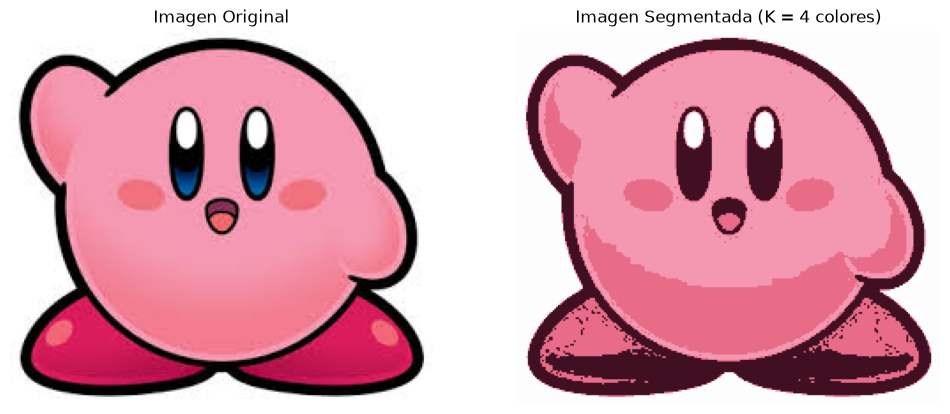

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from PIL import Image 

# =========================================================================
# PASO 1: CARGAR LA IMAGEN Y PREPARAR LA MATRIZ (Código anterior)
# =========================================================================
# Recuerda verificar que el nombre de usuario 'SUSANA' y la imagen sean correctos
image_path = '/home/SUSANA/diplomado-ciencia-de-datos/asset/images.jpg' 
image = Image.open(image_path).convert('RGB') 

# Convertir la imagen en un arreglo de NumPy
img_array = np.array(image) 

# Transformar la estructura 3D a una matriz 2D (columnas de RGB)
h, w, c = img_array.shape 
X = img_array.reshape(-1, 3) 

print(f"Dimensiones originales: {h} filas x {w} columnas.") 
print(f"Matriz transformada para K-Means (X): {X.shape}\n") 


# =========================================================================
# NUEVO CÓDIGO - PARTE 1: CONFIGURACIÓN E INICIALIZACIÓN
# =========================================================================
# Definir el número de colores dominantes que queremos encontrar (ej. K = 4)
K = 4 
epochs = 3 

np.random.seed(42)
# Inicializar centroides seleccionando K píxeles aleatorios de la matriz X
random_indices = np.random.choice(X.shape[0], K, replace=False)
centroids = X[random_indices].astype(float)

print(f"=== INICIANDO K-MEANS PARA CUANTIZACIÓN DE COLOR (K={K}) ===")
print(f"Centroides iniciales (Colores RGB):\n{centroids.astype(int)}\n")


# =========================================================================
# NUEVO CÓDIGO - PARTE 2: EL BUCLE DE ENTRENAMIENTO (K-MEANS)
# =========================================================================
for epoch in range(epochs):
    # # 2. CÁLCULO DE LA MATRIZ DE DISTANCIAS EUCLIDIANAS
    # Distancia de cada píxel (N píxeles) a cada centroide (K centroides)
    # Forma resultante: (N_píxeles, K)
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    
    # # 3. MATRIZ DE PERTENENCIA / ASIGNACIÓN
    # Para cada píxel, determinamos el índice del centroide más cercano (menor distancia)
    # Esto genera un vector de etiquetas de tamaño (N_píxeles,)
    labels = np.argmin(distances, axis=1)
    
    # # Opcional: Mostrar un resumen matemático de la pertenencia en la primera época
    if epoch == 0:
        print(f"Dimensiones de la matriz de distancias: {distances.shape}")
        print(f"Primeros 5 registros de la Matriz de Pertenencia (Asignación a cluster): {labels[:5]}")
        print("-" * 60)
        
    # # 4. ACTUALIZACIÓN DE CENTROIDES (Mover al centro de masa del cluster)
    new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(K)])
    
    # # Condición de convergencia (si los centroides ya no se mueven)
    if np.allclose(centroids, new_centroids):
        print(f"¡K-Means convergió matemáticamente en la época {epoch + 1}!")
        break
        
    centroids = new_centroids
    print(f"Época {epoch + 1}: Centroides actualizados:\n{centroids.astype(int)}\n")

print("¡Proceso de agrupamiento por K-Means completado con éxito!")

# =========================================================================
# PASO 5: MOSTRAR LA IMAGEN RECONSTRUIDA POR K-MEANS
# =========================================================================
# Reasignar a cada píxel el color exacto de su centroide asignado
X_reconstructed = centroids[labels].astype(np.uint8)

# Regresar la matriz estirada a su forma original de imagen (Alto, Ancho, Canales)
img_reconstructed = X_reconstructed.reshape(h, w, c)

# Dibujar ambas imágenes lado a lado para comparar
plt.figure(figsize=(12, 6))

# 1. Mostrar la original
plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.axis('off')
plt.title("Imagen Original")

# 2. Mostrar la segmentada con los K colores dominantes
plt.subplot(1, 2, 2)
plt.imshow(img_reconstructed)
plt.axis('off')
plt.title(f"Imagen Segmentada (K = {K} colores)")
plt.show() 